# Variable-cleaning audit for fighter style clustering

This notebook covers the cleaning checks discussed in the 10-15 meeting: variable definitions and spread, missing values, redundant variables, zero-inflated variables, and scaling. All alternatives are evaluated on in-memory copies only. No source data file is modified or written.

## Load the data

The next block loads the fighter-level dataset and creates a numeric working copy for the audit.

In [1]:
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 140)

# Resolve the path both when the notebook is run from styles/ and from the repository root.
notebook_dir = Path.cwd()
data_path = (notebook_dir.parent / 'data_clean' / 'fighter_career_stats.csv').resolve()
if not data_path.exists():
    data_path = (notebook_dir / 'data_clean' / 'fighter_career_stats.csv').resolve()
if not data_path.exists():
    raise FileNotFoundError(f'Could not find fighter_career_stats.csv from {Path.cwd()}')

source_hash_before = hashlib.sha256(data_path.read_bytes()).hexdigest()
raw_data = pd.read_csv(data_path)
working_data = raw_data.copy(deep=True)

numeric_columns = working_data.select_dtypes(include='number').columns.tolist()
features = working_data[numeric_columns].copy()

print(f'Data file: {data_path}')
print(f'Rows: {len(working_data):,}')
print(f'Numeric variables under review: {len(numeric_columns)}')
print(f'Source hash recorded: {source_hash_before[:16]}...')
display(working_data.head())

Data file: E:\Libraries\Documents\GitHub\UFC-Predictions\data_clean\fighter_career_stats.csv
Rows: 2,683
Numeric variables under review: 55
Source hash recorded: 983e8ba7c8616a0c...


,fighter,total_fights,total_fight_time,fight_quickness,win_DEC_pct,win_KO_TKO_pct,win_SUB_pct,loss_DEC_pct,loss_KO_TKO_pct,loss_SUB_pct,...,DISTANCE_absorbed_per_min,DISTANCE_opp_att_per_min,CLINCH_land_per_min,CLINCH_att_per_min,CLINCH_absorbed_per_min,CLINCH_opp_att_per_min,GROUND_land_per_min,GROUND_att_per_min,GROUND_absorbed_per_min,GROUND_opp_att_per_min
0,AJ Cunningham,2,1176,0.653333,0.0,0.0,0.0,0.500000,0.500000,0.000000,...,3.673469,5.867347,0.102041,0.153061,0.102041,0.102041,0.000000,0.000000,0.204082,0.306122
1,AJ Dobson,4,2973,0.825833,1.0,0.0,0.0,0.666667,0.333333,0.000000,...,4.036327,8.193744,0.363269,0.585267,0.423814,0.605449,0.141271,0.262361,1.150353,1.614531
2,AJ Fletcher,4,2769,0.769167,0.0,0.0,1.0,0.666667,0.000000,0.333333,...,3.250271,6.717226,0.260022,0.433369,0.650054,0.888407,0.216685,0.390033,0.866739,1.170098
3,Aalon Cruz,2,185,0.102778,0.0,0.0,0.0,0.000000,1.000000,0.000000,...,2.918919,4.540541,0.000000,0.000000,2.270270,2.594595,0.000000,0.000000,15.891892,22.702703
4,Aaron Brink,1,55,0.061111,0.0,0.0,0.0,0.000000,0.000000,1.000000,...,2.181818,2.181818,0.000000,2.181818,0.000000,2.181818,0.000000,0.000000,0.000000,0.000000


The dataset has 2,683 fighters and 55 numeric variables. The audit uses a deep in-memory copy, and the source hash is recorded so the final check can verify that the CSV was not changed.

## Review variable meaning, units, and spread

This block summarizes each variable's observed range, missingness, number of distinct values, and unit-like suffix. The plots show the number of variables in each metric family and the variables with the greatest raw interquartile range.

,variable,family,units,missing,missing_pct,n_unique,minimum,maximum,median,iqr,std_dev
0,total_fights,career/time,count,0,0.000000,38,1.000000,47.000000,4.000000,7.000000,6.155953
1,total_fight_time,career/time,seconds,0,0.000000,2092,8.000000,31963.000000,2617.000000,4454.000000,4421.818216
2,fight_quickness,career/time,ratio,0,0.000000,2074,0.011111,1.000000,0.665714,0.325872,0.248324
3,win_DEC_pct,outcome,proportion,0,0.000000,78,0.000000,1.000000,0.200000,0.605556,0.371124
4,win_KO_TKO_pct,outcome,proportion,0,0.000000,77,0.000000,1.000000,0.000000,0.400000,0.323704
5,win_SUB_pct,outcome,proportion,0,0.000000,68,0.000000,1.000000,0.000000,0.200000,0.272168
6,loss_DEC_pct,outcome,proportion,0,0.000000,55,0.000000,1.000000,0.428571,0.666667,0.369874
7,loss_KO_TKO_pct,outcome,proportion,0,0.000000,47,0.000000,1.000000,0.250000,0.500000,0.350492
8,loss_SUB_pct,outcome,proportion,0,0.000000,44,0.000000,1.000000,0.000000,0.333333,0.305095
9,TOTAL_STR_acc,accuracy/defense,proportion,0,0.000000,2260,0.000000,1.000000,0.535194,0.152019,0.140916


Variables with two or fewer observed values:


,family,units,n_unique,minimum,maximum


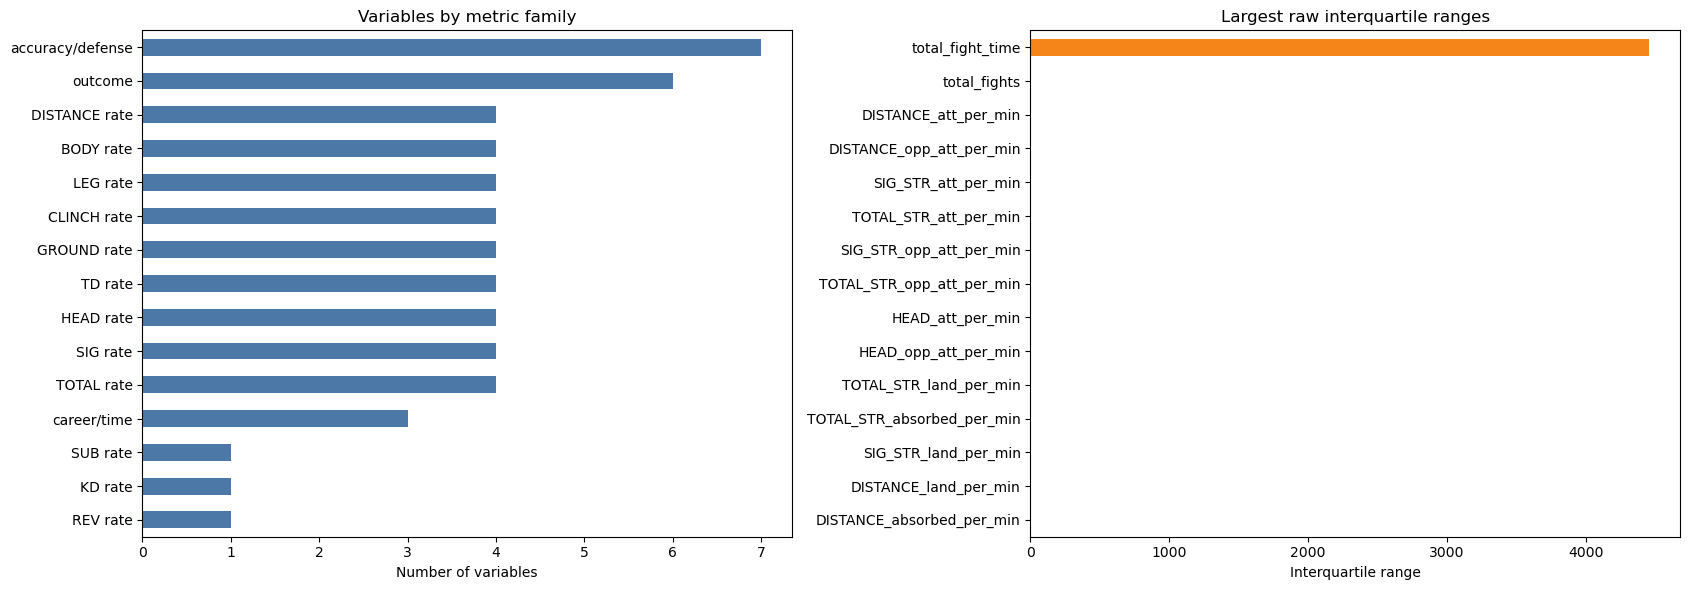

In [2]:
def metric_family(column_name):
    if column_name in {'total_fights', 'total_fight_time', 'fight_quickness'}:
        return 'career/time'
    if column_name.startswith(('win_', 'loss_')):
        return 'outcome'
    if column_name.endswith('_acc') or column_name.endswith('_def') or column_name.endswith('_pct'):
        return 'accuracy/defense'
    if column_name.endswith('_per_min'):
        return column_name.split('_')[0] + ' rate'
    return column_name.split('_')[0]


def metric_units(column_name):
    if column_name == 'total_fights':
        return 'count'
    if column_name == 'total_fight_time':
        return 'seconds'
    if column_name == 'fight_quickness':
        return 'ratio'
    if column_name.endswith(('_pct', '_acc', '_def')):
        return 'proportion'
    if column_name.endswith('_per_min'):
        return 'rate per minute'
    return 'numeric'


variable_audit = pd.DataFrame(index=numeric_columns)
variable_audit['family'] = [metric_family(column) for column in numeric_columns]
variable_audit['units'] = [metric_units(column) for column in numeric_columns]
variable_audit['missing'] = features.isna().sum()
variable_audit['missing_pct'] = features.isna().mean().mul(100)
variable_audit['n_unique'] = features.nunique(dropna=True)
variable_audit['minimum'] = features.min()
variable_audit['maximum'] = features.max()
variable_audit['median'] = features.median()
variable_audit['iqr'] = features.quantile(0.75) - features.quantile(0.25)
variable_audit['std_dev'] = features.std()

display(variable_audit.reset_index(names='variable'))
print('Variables with two or fewer observed values:')
display(variable_audit[variable_audit['n_unique'] <= 2][['family', 'units', 'n_unique', 'minimum', 'maximum']])

family_counts = variable_audit['family'].value_counts().sort_values()
top_iqr = variable_audit['iqr'].sort_values(ascending=False).head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
family_counts.plot(kind='barh', ax=axes[0], color='#4c78a8')
axes[0].set_title('Variables by metric family')
axes[0].set_xlabel('Number of variables')
axes[0].set_ylabel('')

top_iqr.plot(kind='barh', ax=axes[1], color='#f58518')
axes[1].set_title('Largest raw interquartile ranges')
axes[1].set_xlabel('Interquartile range')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

All 55 variables have more than two observed values, so no variable is constant or nearly constant by this simple screen. The data mix counts, seconds, proportions, and per-minute rates: for example, total_fight_time ranges from 8 to 31,963 seconds while proportion variables range from 0 to 1. The large metric families also contain related landed, attempted, and absorbed measures; those relationships are examined explicitly in the correlation section. The spread plot is a screening aid, not a final measure of substantive importance—variable importance still needs subject-matter review.

## Check missing values and compare the discussed local options

This block measures missingness and compares mean imputation with the existing TD_def removal option. Both alternatives remain in memory; neither is written back to the dataset.

Missing-value summary:


,missing_cells
TD_def,232


,variables,remaining_missing_cells,removed_TD_def
original,55,232,False
mean imputation,55,0,False
drop TD_def,54,0,True


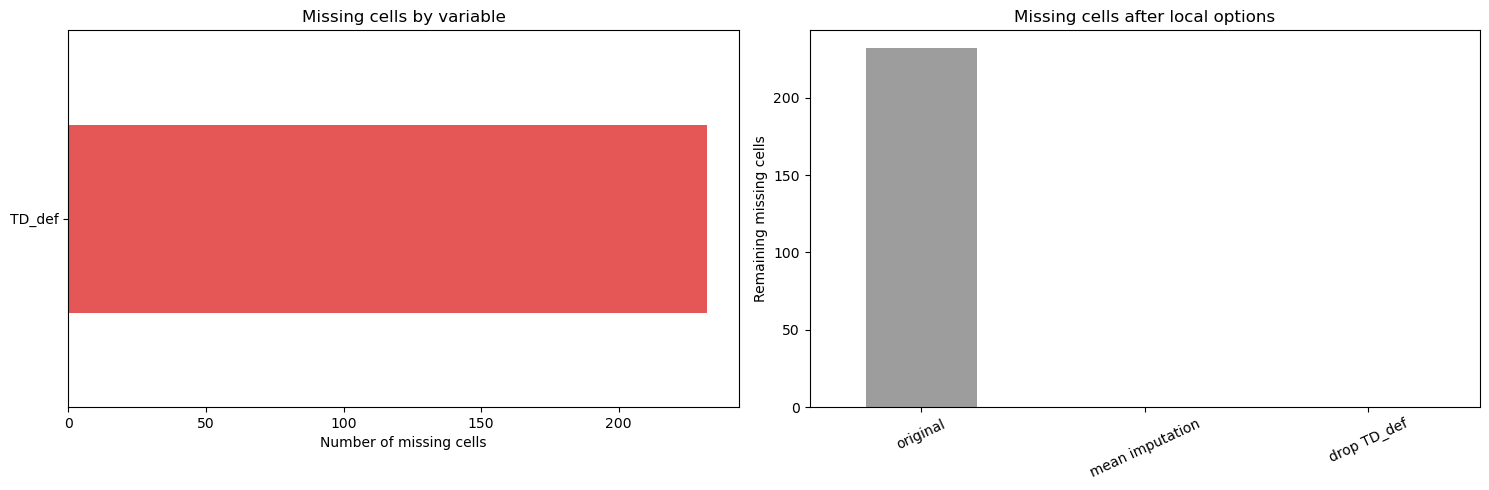

In [3]:
missing_counts = features.isna().sum().sort_values(ascending=False)
missing_positive = missing_counts[missing_counts > 0]

# Option 1: mean-impute each variable using only its observed values.
column_means = features.mean()
mean_imputed = features.fillna(column_means)

# Option 2: remove TD_def locally, matching the option in the existing R workflow.
td_def_removed = features.drop(columns=['TD_def'], errors='ignore').copy()

if mean_imputed.isna().any().any():
    unresolved = mean_imputed.columns[mean_imputed.isna().any()].tolist()
    raise ValueError(f'Mean imputation could not resolve missing values in: {unresolved}')

missing_options = pd.DataFrame({
    'variables': [features.shape[1], mean_imputed.shape[1], td_def_removed.shape[1]],
    'remaining_missing_cells': [
        int(features.isna().sum().sum()),
        int(mean_imputed.isna().sum().sum()),
        int(td_def_removed.isna().sum().sum()),
    ],
    'removed_TD_def': [False, False, 'TD_def' in features.columns and 'TD_def' not in td_def_removed.columns],
}, index=['original', 'mean imputation', 'drop TD_def'])

print('Missing-value summary:')
display(missing_positive.to_frame('missing_cells'))
display(missing_options)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
if missing_positive.empty:
    axes[0].text(0.5, 0.5, 'No missing feature values found', ha='center', va='center')
    axes[0].set_axis_off()
else:
    missing_positive.sort_values().plot(kind='barh', ax=axes[0], color='#e45756')
    axes[0].set_title('Missing cells by variable')
    axes[0].set_xlabel('Number of missing cells')
    axes[0].set_ylabel('')

missing_options['remaining_missing_cells'].plot(kind='bar', ax=axes[1], color=['#9d9d9d', '#54a24b', '#4c78a8'])
axes[1].set_title('Missing cells after local options')
axes[1].set_ylabel('Remaining missing cells')
axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

Only TD_def has missing values: 232 of 2,683 fighters, or 8.65%. Mean imputation removes all 232 missing cells while retaining 55 variables; dropping TD_def leaves 54 variables and also produces a complete matrix. Because the missingness has a domain-specific meaning—no opponent takedown attempts—the notebook preserves both local options for discussion rather than silently choosing one.

## Check highly correlated or redundant variables

This block calculates pairwise Pearson correlations on the local mean-imputed copy, lists the strongest pairs, and visualizes the full correlation structure. No correlated variable is automatically removed.

Non-constant variables used for correlations: 55
Pairs with absolute correlation >= 0.90: 17


,variable_1,variable_2,correlation,absolute_correlation
0,SIG_STR_opp_att_per_min,HEAD_opp_att_per_min,0.972578,0.972578
1,GROUND_land_per_min,GROUND_att_per_min,0.967093,0.967093
2,SIG_STR_att_per_min,HEAD_att_per_min,0.965292,0.965292
3,GROUND_absorbed_per_min,GROUND_opp_att_per_min,0.965274,0.965274
4,CLINCH_absorbed_per_min,CLINCH_opp_att_per_min,0.963336,0.963336
5,SIG_STR_att_per_min,DISTANCE_att_per_min,0.951842,0.951842
6,BODY_absorbed_per_min,BODY_opp_att_per_min,0.949675,0.949675
7,SIG_STR_absorbed_per_min,HEAD_absorbed_per_min,0.948535,0.948535
8,total_fights,total_fight_time,0.947992,0.947992
9,CLINCH_land_per_min,CLINCH_att_per_min,0.947218,0.947218


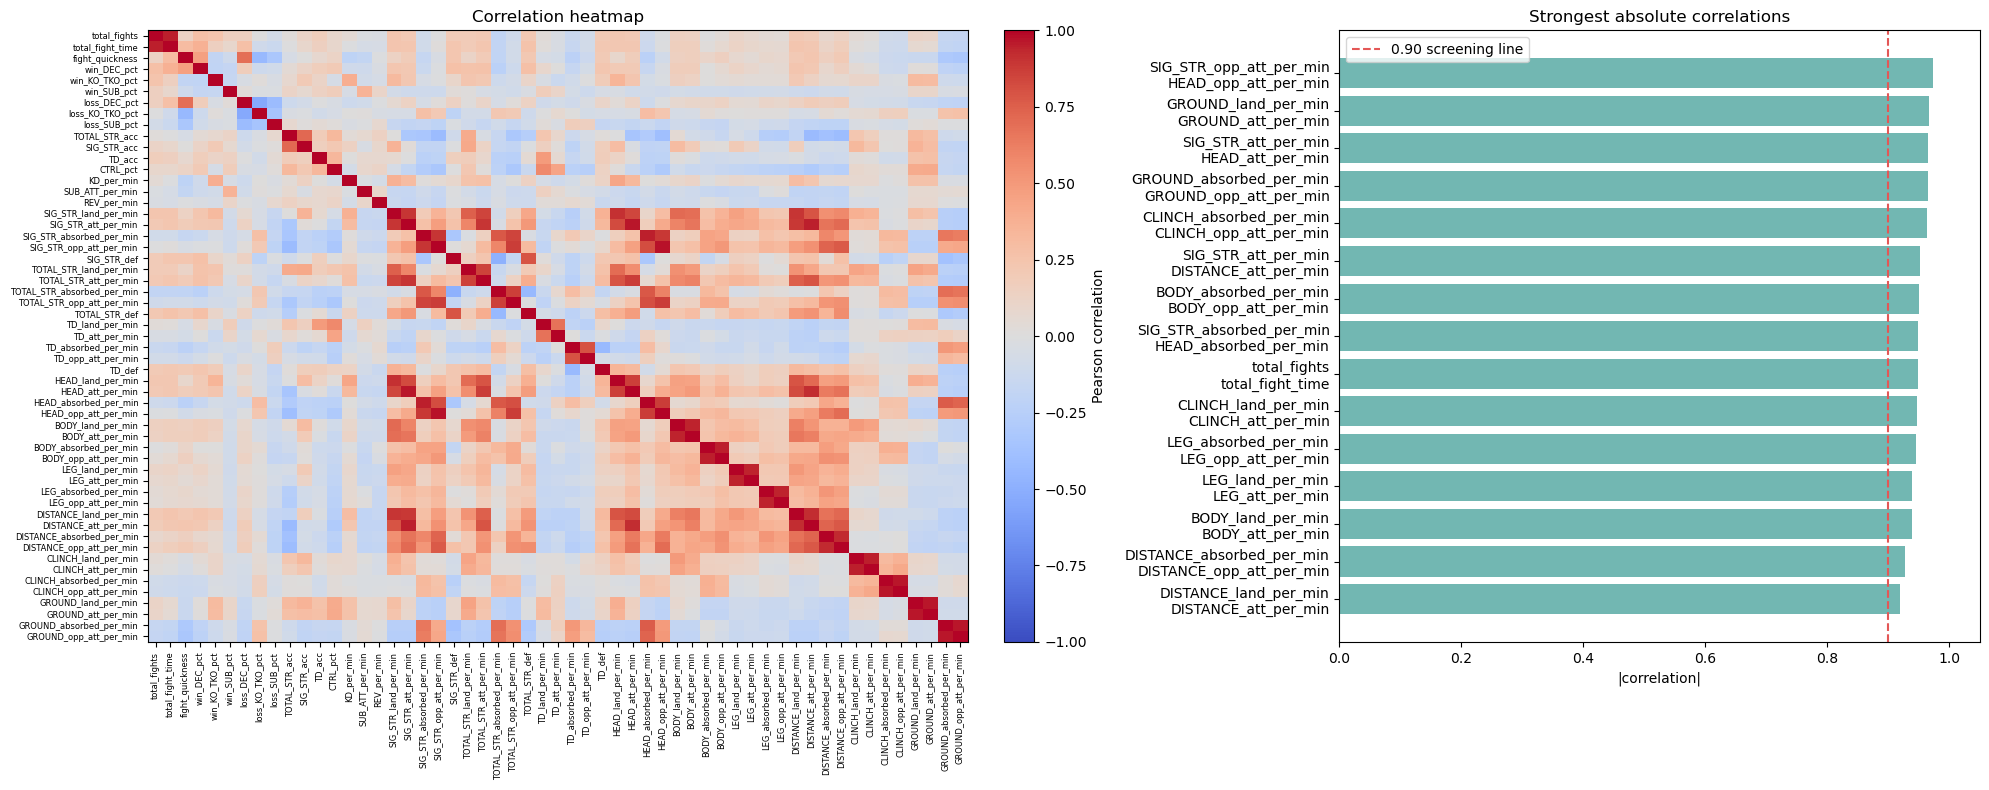

In [4]:
non_constant_columns = mean_imputed.columns[mean_imputed.nunique(dropna=False) > 1].tolist()
correlation_matrix = mean_imputed[non_constant_columns].corr()
upper_mask = np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)
pair_values = correlation_matrix.where(upper_mask).stack().sort_values(ascending=False)

correlation_pairs = pd.DataFrame({
    'variable_1': [pair[0] for pair in pair_values.index],
    'variable_2': [pair[1] for pair in pair_values.index],
    'correlation': pair_values.to_numpy(),
})
correlation_pairs['absolute_correlation'] = correlation_pairs['correlation'].abs()
correlation_pairs = correlation_pairs.sort_values('absolute_correlation', ascending=False).reset_index(drop=True)
strong_correlation_pairs = correlation_pairs[correlation_pairs['absolute_correlation'] >= 0.90]

print(f'Non-constant variables used for correlations: {len(non_constant_columns)}')
print(f'Pairs with absolute correlation >= 0.90: {len(strong_correlation_pairs)}')
display(correlation_pairs.head(20))

fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={'width_ratios': [1.4, 1]})
image = axes[0].imshow(correlation_matrix, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
axes[0].set_title('Correlation heatmap')
axes[0].set_xticks(range(len(non_constant_columns)))
axes[0].set_xticklabels(non_constant_columns, rotation=90, fontsize=6)
axes[0].set_yticks(range(len(non_constant_columns)))
axes[0].set_yticklabels(non_constant_columns, fontsize=6)
fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04, label='Pearson correlation')

top_pairs = correlation_pairs.head(15).copy()
if top_pairs.empty:
    axes[1].text(0.5, 0.5, 'No variable pairs available', ha='center', va='center')
    axes[1].set_axis_off()
else:
    labels = (top_pairs['variable_1'] + '\n' + top_pairs['variable_2']).iloc[::-1]
    values = top_pairs['absolute_correlation'].iloc[::-1]
    axes[1].barh(labels, values, color='#72b7b2')
    axes[1].axvline(0.90, color='#e45756', linestyle='--', label='0.90 screening line')
    axes[1].set_xlim(0, 1.05)
    axes[1].set_title('Strongest absolute correlations')
    axes[1].set_xlabel('|correlation|')
    axes[1].legend()
plt.tight_layout()
plt.show()

There are 17 pairs with absolute correlation at least 0.90. The strongest are SIG_STR_opp_att_per_min with HEAD_opp_att_per_min (0.973), GROUND_land_per_min with GROUND_att_per_min (0.967), and SIG_STR_att_per_min with HEAD_att_per_min (0.965); total_fights and total_fight_time are also strongly related (0.948). These relationships show substantial redundancy within measurement families. The 0.90 line is a screening threshold, not an automatic deletion rule: each candidate pair should be reviewed for its distinct interpretation before clustering.

## Identify zero-inflated variables

This block measures the percentage of observed values equal to zero. A 50% line is used only to flag variables for review; zero values are not replaced automatically.

Variables flagged at the 50% screening level: 5


,zero_pct,missing_cells,median,metric_family
win_SUB_pct,68.691763,0,0.000000,outcome
loss_SUB_pct,58.777488,0,0.000000,outcome
REV_per_min,58.404771,0,0.000000,REV rate
win_KO_TKO_pct,56.913902,0,0.000000,outcome
KD_per_min,53.373090,0,0.000000,KD rate
win_DEC_pct,47.185986,0,0.200000,outcome
SUB_ATT_per_min,42.750652,0,0.015096,SUB rate
loss_KO_TKO_pct,41.595229,0,0.250000,outcome
loss_DEC_pct,33.656355,0,0.428571,outcome
TD_land_per_min,23.853895,0,0.066667,TD rate


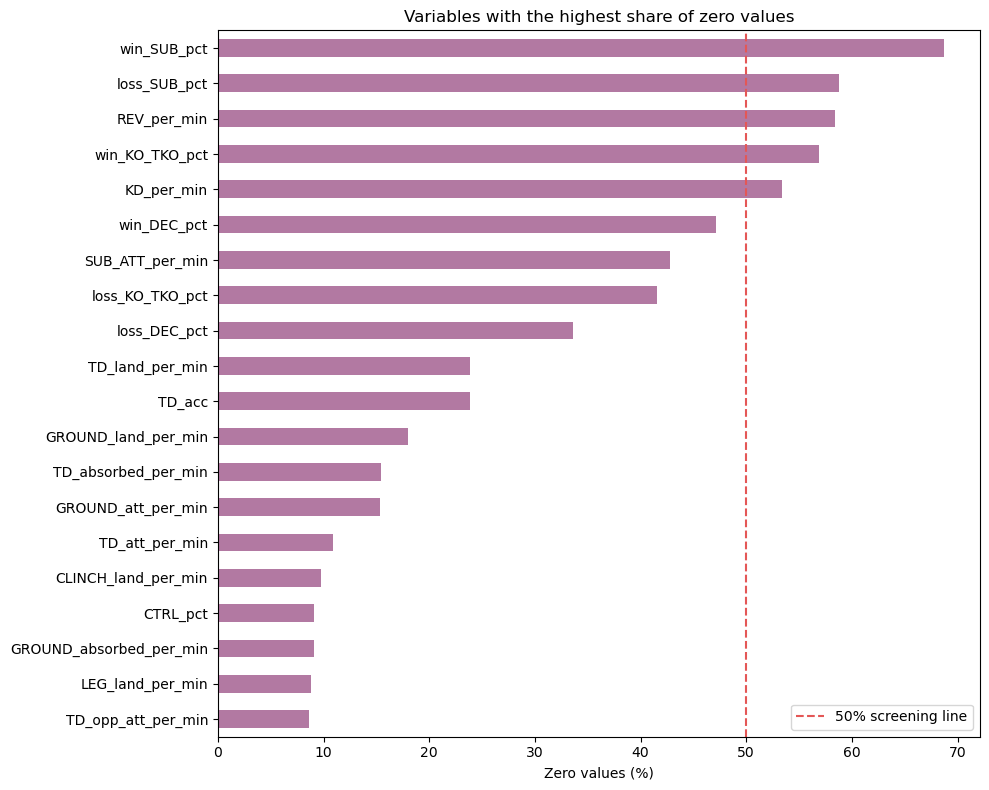

In [5]:
zero_rate = features.eq(0).mean().mul(100).sort_values(ascending=False)
zero_inflated = zero_rate[zero_rate >= 50]

zero_summary = pd.DataFrame({
    'zero_pct': zero_rate,
    'missing_cells': features.isna().sum(),
    'median': features.median(),
    'metric_family': pd.Series({column: metric_family(column) for column in features.columns}),
}).sort_values('zero_pct', ascending=False)

print(f'Variables flagged at the 50% screening level: {len(zero_inflated)}')
display(zero_summary.head(20))

plot_zero_rate = zero_rate.head(20).sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
plot_zero_rate.plot(kind='barh', ax=ax, color='#b279a2')
ax.axvline(50, color='#e45756', linestyle='--', label='50% screening line')
ax.set_title('Variables with the highest share of zero values')
ax.set_xlabel('Zero values (%)')
ax.set_ylabel('')
ax.legend()
plt.tight_layout()
plt.show()

Five variables meet the 50% screening level: win_SUB_pct (68.7% zeros), loss_SUB_pct (58.8%), REV_per_min (58.4%), win_KO_TKO_pct (56.9%), and KD_per_min (53.4%). win_DEC_pct is close at 47.2%. These zeros are generally meaningful—no event was recorded—so replacing them with missing values or deleting the variables would change their meaning. The next decision is variable-specific: inspect why each variable is sparse and whether its scale or event definition is appropriate for clustering.

## Compare raw scales with local standardization

This block checks the normalization/standardization concern by comparing representative raw distributions with z-score-scaled versions. Scaling is performed on an in-memory copy only.

,raw_min,raw_max,raw_std,z_score_mean,z_score_std
total_fights,1.000000,47.000000,6.155953,3.972472e-17,1.0
total_fight_time,8.000000,31963.000000,4421.818216,7.067689e-17,1.0
fight_quickness,0.011111,1.000000,0.248324,-1.920028e-16,1.0
SIG_STR_acc,0.000000,1.000000,0.130131,-1.231466e-16,1.0
SIG_STR_land_per_min,0.000000,20.487805,1.689529,1.747887e-16,1.0
TD_def,0.000000,1.000000,0.265674,-9.798763e-17,1.0


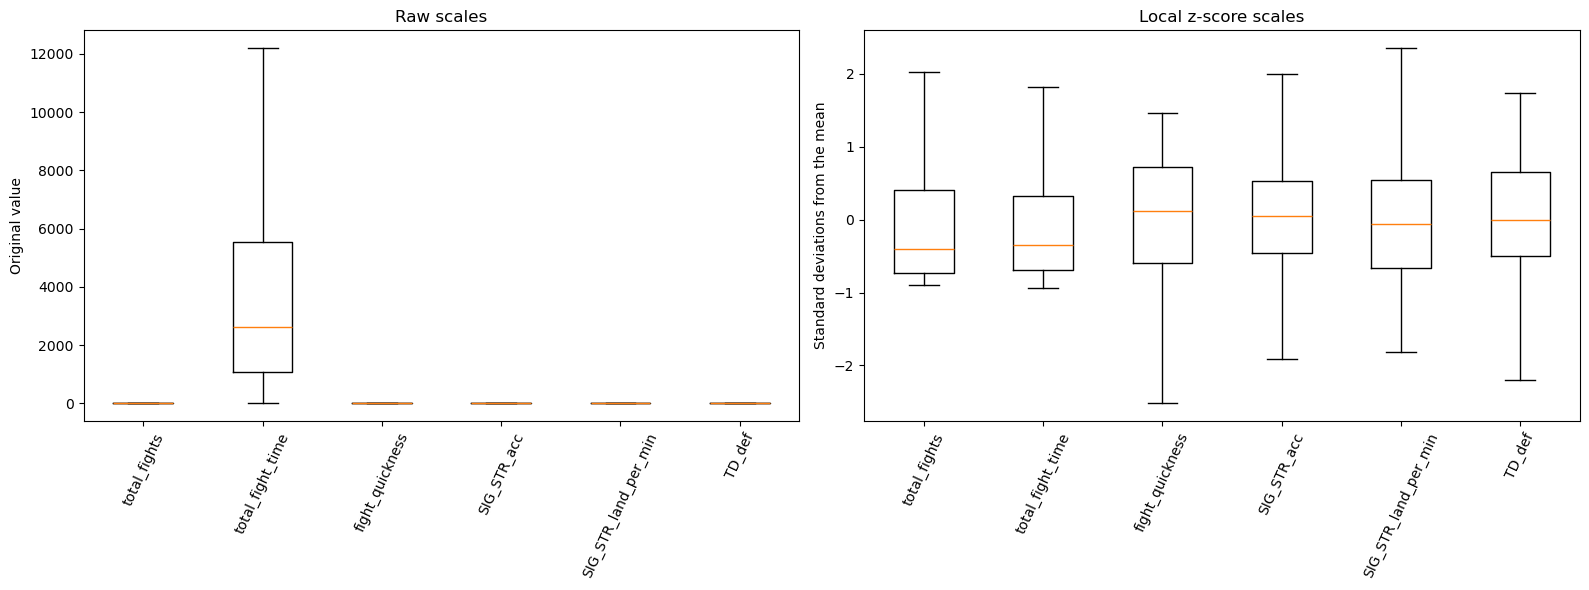

In [6]:
preferred_representatives = [
    'total_fights',
    'total_fight_time',
    'fight_quickness',
    'SIG_STR_acc',
    'SIG_STR_land_per_min',
    'TD_def',
]
representatives = [column for column in preferred_representatives if column in features.columns]

scaled_features = (mean_imputed - mean_imputed.mean()) / mean_imputed.std(ddof=0).replace(0, 1)
scaling_summary = pd.DataFrame({
    'raw_min': features[representatives].min(),
    'raw_max': features[representatives].max(),
    'raw_std': features[representatives].std(),
    'z_score_mean': scaled_features[representatives].mean(),
    'z_score_std': scaled_features[representatives].std(ddof=0),
})
display(scaling_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
raw_values = [features[column].dropna().to_numpy() for column in representatives]
scaled_values = [scaled_features[column].to_numpy() for column in representatives]
axes[0].boxplot(raw_values, tick_labels=representatives, showfliers=False)
axes[0].set_title('Raw scales')
axes[0].set_ylabel('Original value')
axes[0].tick_params(axis='x', rotation=65)
axes[1].boxplot(scaled_values, tick_labels=representatives, showfliers=False)
axes[1].set_title('Local z-score scales')
axes[1].set_ylabel('Standard deviations from the mean')
axes[1].tick_params(axis='x', rotation=65)
plt.tight_layout()
plt.show()

The raw variables use materially different units and ranges: total_fights ranges from 1 to 47, total_fight_time from 8 to 31,963 seconds, and SIG_STR_land_per_min from 0 to 20.49, while the proportion examples range from 0 to 1. The local z-score version has mean approximately 0 and population standard deviation 1 for every displayed variable. This supports centering and scaling before distance-based clustering; it does not decide whether a different transformation is needed for sparse or highly skewed variables.

## Keep the cleaning decision local and verify the source file

The final block reports the in-memory alternatives and verifies that the original CSV hash is unchanged. No cleaned data are exported.

In [7]:
local_cleaning_options = {
    'original numeric features': features,
    'mean-imputed features': mean_imputed,
    'TD_def removed locally': td_def_removed,
}
local_summary = pd.DataFrame({
    'rows': {name: frame.shape[0] for name, frame in local_cleaning_options.items()},
    'variables': {name: frame.shape[1] for name, frame in local_cleaning_options.items()},
    'missing_cells': {name: int(frame.isna().sum().sum()) for name, frame in local_cleaning_options.items()},
})

source_hash_after = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert source_hash_before == source_hash_after, 'The source CSV changed during the notebook run.'

print('Local cleaning options:')
display(local_summary)
print(f'Source CSV unchanged: {source_hash_before == source_hash_after}')
print('No cleaned data file was written by this notebook.')

Local cleaning options:


,rows,variables,missing_cells
original numeric features,2683,55,232
mean-imputed features,2683,55,0
TD_def removed locally,2683,54,0


Source CSV unchanged: True
No cleaned data file was written by this notebook.


The source CSV hash is unchanged, and the run wrote no cleaned data file. The local options are: 55 variables with 232 missing cells in the original numeric matrix, 55 variables with 0 missing cells after mean imputation, or 54 variables with 0 missing cells after locally removing TD_def. The defensible next step is to review the TD_def mechanism, the strongest redundant variable pairs, and the five zero-heavy metrics with domain knowledge before making any permanent feature decision.